# UCS420: Cognitive Computing — Assignment 10
## Heart Health Information Assistant
**Roll Number:** 1024170044 (Even)  
**Assigned topic:** Heart Health Information Assistant


## 1. Install and import libraries

In [7]:
!pip -q install nltk scikit-learn pandas matplotlib seaborn ipywidgets

In [8]:
import re, nltk, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
print("Libraries imported successfully.")

Libraries imported successfully.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## 2. Labelled corpus — 60 queries across 6 intents

In [9]:
data = [
("What are warning signs of a heart attack?", "heart_attack_symptoms"),
("I have chest pressure and sweating", "heart_attack_symptoms"),
("Can a heart attack cause jaw pain?", "heart_attack_symptoms"),
("What does a heart attack feel like?", "heart_attack_symptoms"),
("Can arm pain be related to a heart attack?", "heart_attack_symptoms"),
("Is sudden breathlessness a heart warning sign?", "heart_attack_symptoms"),
("What symptoms should make me worry about a heart attack?", "heart_attack_symptoms"),
("Can nausea and dizziness occur during a heart attack?", "heart_attack_symptoms"),
("What are common cardiac emergency symptoms?", "heart_attack_symptoms"),
("Does heart attack discomfort spread to the back?", "heart_attack_symptoms"),
("What is blood pressure?", "blood_pressure"),
("Explain systolic and diastolic pressure", "blood_pressure"),
("What can cause high blood pressure?", "blood_pressure"),
("How can I monitor blood pressure at home?", "blood_pressure"),
("What does hypertension mean?", "blood_pressure"),
("Why is low blood pressure a concern?", "blood_pressure"),
("How does salt affect blood pressure?", "blood_pressure"),
("What is a blood pressure reading?", "blood_pressure"),
("Can stress affect blood pressure?", "blood_pressure"),
("Why should blood pressure be checked regularly?", "blood_pressure"),
("What is cholesterol?", "cholesterol"),
("Explain LDL and HDL cholesterol", "cholesterol"),
("Why is high LDL harmful?", "cholesterol"),
("How can I maintain healthy cholesterol?", "cholesterol"),
("What are triglycerides?", "cholesterol"),
("Which foods can raise LDL cholesterol?", "cholesterol"),
("What is a lipid profile test?", "cholesterol"),
("How often should cholesterol be checked?", "cholesterol"),
("Does exercise help improve cholesterol?", "cholesterol"),
("Difference between good and bad cholesterol?", "cholesterol"),
("What food is good for heart health?", "healthy_lifestyle"),
("How much activity supports heart health?", "healthy_lifestyle"),
("Give me heart healthy diet tips", "healthy_lifestyle"),
("How does smoking affect the heart?", "healthy_lifestyle"),
("Can good sleep support heart health?", "healthy_lifestyle"),
("How can I reduce salt in meals?", "healthy_lifestyle"),
("What habits help prevent heart disease?", "healthy_lifestyle"),
("Does walking benefit the heart?", "healthy_lifestyle"),
("How can stress management help my heart?", "healthy_lifestyle"),
("Why avoid tobacco for a healthy heart?", "healthy_lifestyle"),
("What is an ECG test?", "heart_tests"),
("Why recommend an echocardiogram?", "heart_tests"),
("What happens during a stress test?", "heart_tests"),
("What is an angiogram used for?", "heart_tests"),
("How does an ECG record heart activity?", "heart_tests"),
("What is an echocardiogram?", "heart_tests"),
("Why order a cardiac blood test?", "heart_tests"),
("What is a treadmill test for the heart?", "heart_tests"),
("What does a heart ultrasound show?", "heart_tests"),
("How should I prepare for a heart test?", "heart_tests"),
("Why are medicines prescribed for heart conditions?", "medication_care"),
("What should I ask about a heart medicine?", "medication_care"),
("Why take prescribed medicine regularly?", "medication_care"),
("Can I stop blood pressure medicine on my own?", "medication_care"),
("What if I miss a prescribed dose?", "medication_care"),
("How can I track my heart medicines?", "medication_care"),
("Can medicines have side effects?", "medication_care"),
("Should I discuss supplements with my doctor?", "medication_care"),
("Why follow prescription instructions?", "medication_care"),
("Who can explain my heart medication schedule?", "medication_care")
]
df = pd.DataFrame(data, columns=["query", "intent"])
print("Total queries:", len(df), "| Intent categories:", df.intent.nunique())
display(df.head(10))
display(df.intent.value_counts().to_frame("query_count"))

Total queries: 60 | Intent categories: 6


,query,intent
0,What are warning signs of a heart attack?,heart_attack_symptoms
1,I have chest pressure and sweating,heart_attack_symptoms
2,Can a heart attack cause jaw pain?,heart_attack_symptoms
3,What does a heart attack feel like?,heart_attack_symptoms
4,Can arm pain be related to a heart attack?,heart_attack_symptoms
5,Is sudden breathlessness a heart warning sign?,heart_attack_symptoms
6,What symptoms should make me worry about a hea...,heart_attack_symptoms
7,Can nausea and dizziness occur during a heart ...,heart_attack_symptoms
8,What are common cardiac emergency symptoms?,heart_attack_symptoms
9,Does heart attack discomfort spread to the back?,heart_attack_symptoms


,query_count
intent,
heart_attack_symptoms,10
blood_pressure,10
cholesterol,10
healthy_lifestyle,10
heart_tests,10
medication_care,10


## 3. Hierarchical taxonomy — 4 major categories, 2 subcategories each

In [10]:
taxonomy = {
 "Heart conditions and warning signs": ["Heart attack symptoms", "General cardiac warning signs"],
 "Cardiovascular measurements": ["Blood pressure", "Cholesterol and lipid profile"],
 "Prevention and daily care": ["Healthy lifestyle", "Medication and care"],
 "Clinical assessment": ["Heart tests", "Medical follow-up"]
}
for major, subs in taxonomy.items():
    print(major)
    for sub in subs: print("  -", sub)

Heart conditions and warning signs
  - Heart attack symptoms
  - General cardiac warning signs
Cardiovascular measurements
  - Blood pressure
  - Cholesterol and lipid profile
Prevention and daily care
  - Healthy lifestyle
  - Medication and care
Clinical assessment
  - Heart tests
  - Medical follow-up


## 4. Domain concepts and relationships

In [11]:
concepts = [
 "Heart", "Blood pressure", "Cholesterol", "LDL", "HDL", "Triglycerides",
 "Arteries", "Heart attack", "ECG", "Echocardiogram", "Physical activity",
 "Healthy diet", "Smoking", "Medication", "Doctor"
]
relationships = [
 ("High blood pressure", "increases risk of", "Heart disease"),
 ("High LDL", "can contribute to", "Artery plaque"),
 ("HDL", "helps transport", "Cholesterol"),
 ("Triglycerides", "are measured in", "Lipid profile"),
 ("Artery blockage", "can cause", "Heart attack"),
 ("ECG", "records electrical activity of", "Heart"),
 ("Echocardiogram", "uses ultrasound to examine", "Heart"),
 ("Physical activity", "supports", "Cardiovascular health"),
 ("Healthy diet", "supports management of", "Cholesterol"),
 ("Smoking", "increases risk of", "Heart disease"),
 ("Doctor", "may prescribe", "Medication"),
 ("Medication", "must be used according to", "Prescription")
]
print("Concepts:", len(concepts), "| Relationships:", len(relationships))
display(pd.DataFrame(relationships, columns=["Concept 1", "Relationship", "Concept 2"]))

Concepts: 15 | Relationships: 12


,Concept 1,Relationship,Concept 2
0,High blood pressure,increases risk of,Heart disease
1,High LDL,can contribute to,Artery plaque
2,HDL,helps transport,Cholesterol
3,Triglycerides,are measured in,Lipid profile
4,Artery blockage,can cause,Heart attack
5,ECG,records electrical activity of,Heart
6,Echocardiogram,uses ultrasound to examine,Heart
7,Physical activity,supports,Cardiovascular health
8,Healthy diet,supports management of,Cholesterol
9,Smoking,increases risk of,Heart disease


## 5. NLP preprocessing: lowercase, tokenization, stopword removal, lemmatization
Important negation words (no, not, never) are retained because they can change meaning.

In [12]:
stop_words = set(stopwords.words("english")) - {"no", "not", "never"}
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()
    tokens = re.findall(r"\b[a-z]+\b", text)
    tokens = [w for w in tokens if w not in stop_words]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return " ".join(tokens)

df["processed_query"] = df["query"].apply(preprocess_text)
display(df[["query", "processed_query", "intent"]].head(12))

,query,processed_query,intent
0,What are warning signs of a heart attack?,warning sign heart attack,heart_attack_symptoms
1,I have chest pressure and sweating,chest pressure sweating,heart_attack_symptoms
2,Can a heart attack cause jaw pain?,heart attack cause jaw pain,heart_attack_symptoms
3,What does a heart attack feel like?,heart attack feel like,heart_attack_symptoms
4,Can arm pain be related to a heart attack?,arm pain related heart attack,heart_attack_symptoms
5,Is sudden breathlessness a heart warning sign?,sudden breathlessness heart warning sign,heart_attack_symptoms
6,What symptoms should make me worry about a hea...,symptom make worry heart attack,heart_attack_symptoms
7,Can nausea and dizziness occur during a heart ...,nausea dizziness occur heart attack,heart_attack_symptoms
8,What are common cardiac emergency symptoms?,common cardiac emergency symptom,heart_attack_symptoms
9,Does heart attack discomfort spread to the back?,heart attack discomfort spread back,heart_attack_symptoms


## 6. TF-IDF feature extraction and Logistic Regression training

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    df.processed_query, df.intent, test_size=0.25, random_state=42, stratify=df.intent
)
tfidf = TfidfVectorizer(ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_vec, y_train)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("TF-IDF features:", len(tfidf.get_feature_names_out()))
print("Model trained successfully.")

Training samples: 45
Testing samples: 15
TF-IDF features: 186
Model trained successfully.


## 7. Evaluation: accuracy, precision, recall, F1-score and confusion matrix

,Metric,Score
0,Accuracy,0.733333
1,Precision (weighted),0.720000
2,Recall (weighted),0.733333
3,F1-score (weighted),0.687778


                       precision    recall  f1-score   support

       blood_pressure       1.00      0.50      0.67         2
          cholesterol       0.50      1.00      0.67         2
    healthy_lifestyle       0.60      1.00      0.75         3
heart_attack_symptoms       1.00      1.00      1.00         3
          heart_tests       1.00      0.67      0.80         3
      medication_care       0.00      0.00      0.00         2

             accuracy                           0.73        15
            macro avg       0.68      0.69      0.65        15
         weighted avg       0.72      0.73      0.69        15



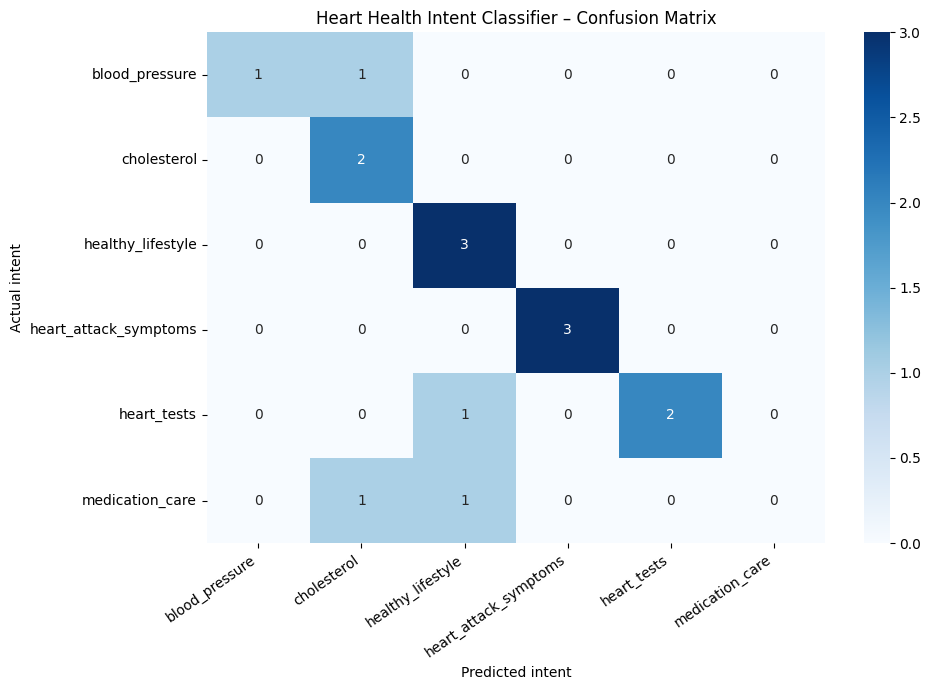

In [14]:
y_pred = model.predict(X_test_vec)
metrics_df = pd.DataFrame({
 "Metric": ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-score (weighted)"],
 "Score": [
  accuracy_score(y_test, y_pred),
  precision_score(y_test, y_pred, average="weighted", zero_division=0),
  recall_score(y_test, y_pred, average="weighted", zero_division=0),
  f1_score(y_test, y_pred, average="weighted", zero_division=0)
 ]
})
display(metrics_df)
print(classification_report(y_test, y_pred, zero_division=0))

labels = model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted intent")
plt.ylabel("Actual intent")
plt.title("Heart Health Intent Classifier – Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 8. Domain-specific heart-health knowledge base

In [15]:
knowledge_base = {
 "heart_attack_symptoms": {
  "title": "Heart attack warning signs",
  "response": "Possible warning signs include chest discomfort or pressure; discomfort in one or both arms, back, neck, jaw or stomach; shortness of breath; cold sweat; nausea; or lightheadedness. Symptoms can vary. If you think someone may be having a heart attack, call emergency services immediately. Do not wait for an online response.",
  "source": "American Heart Association – Warning Signs of a Heart Attack"
 },
 "blood_pressure": {
  "title": "Blood pressure information",
  "response": "Blood pressure is the force of blood against artery walls. A reading has systolic (top) and diastolic (bottom) values. One reading may not represent usual blood pressure. Use a validated monitor correctly and discuss repeated high or low readings with a healthcare professional.",
  "source": "General educational information; consult a healthcare professional"
 },
 "cholesterol": {
  "title": "Cholesterol information",
  "response": "Cholesterol is a waxy substance in blood. LDL is commonly called bad cholesterol and HDL good cholesterol. A lipid profile may measure total cholesterol, LDL, HDL and triglycerides. A clinician should interpret results using your overall health and risk factors.",
  "source": "CDC – Preventing High Cholesterol"
 },
 "healthy_lifestyle": {
  "title": "Heart-healthy lifestyle",
  "response": "Heart-supportive habits include eating vegetables, fruits and whole grains; limiting excess salt and foods high in saturated or trans fats; being physically active as appropriate; avoiding tobacco; getting adequate sleep; and managing stress. Choose changes suitable for your health.",
  "source": "CDC – Preventing Heart Disease"
 },
 "heart_tests": {
  "title": "Common heart tests",
  "response": "An ECG records the heart's electrical activity. An echocardiogram uses ultrasound to create heart images. A stress test observes the heart during increased activity, while an angiogram helps clinicians examine blood vessels. Follow the care team's instructions about any test.",
  "source": "General educational information; ask the ordering clinician"
 },
 "medication_care": {
  "title": "Heart medication and care",
  "response": "Take prescribed medicines only as directed. Do not start, stop, double or change a dose based on this assistant. If a dose is missed or side effects occur, check the medicine leaflet and contact your doctor or pharmacist. Keep an updated medicine list.",
  "source": "General medication-safety guidance; consult your doctor or pharmacist"
 }
}
print("Knowledge base entries:", len(knowledge_base))
for k, v in knowledge_base.items(): print(k, "->", v["title"])

Knowledge base entries: 6
heart_attack_symptoms -> Heart attack warning signs
blood_pressure -> Blood pressure information
cholesterol -> Cholesterol information
healthy_lifestyle -> Heart-healthy lifestyle
heart_tests -> Common heart tests
medication_care -> Heart medication and care


## 9. Rule-based reasoning and response generation
Rules include emergency escalation, low-confidence handling, unsupported health-topic handling, blank-input handling, greeting handling, knowledge retrieval and a safety disclaimer.

In [16]:
EMERGENCY_PATTERNS = [
 r"chest (pain|pressure|tightness|discomfort)",
 r"(crushing|severe) chest",
 r"(shortness of breath|cannot breathe|can't breathe|difficulty breathing)",
 r"(cold sweat|sweating).*(chest|arm|jaw|breath)",
 r"(chest|arm|jaw|back) pain.*(sweat|breath|nausea|faint)",
 r"(face droop|arm weakness|slurred speech|sudden speech difficulty)",
 r"(fainting|unconscious|not breathing)"
]
OUT_OF_SCOPE_TERMS = [
 "toothache", "migraine", "kidney stone", "skin rash",
 "fracture", "ear infection", "pregnancy", "stomach ulcer"
]

def is_emergency(query):
    q = query.lower()
    return any(re.search(p, q) for p in EMERGENCY_PATTERNS)

def assistant_response(query, confidence_threshold=0.40):
    query = query.strip()
    if not query:
        return {"status":"empty", "intent":"none", "confidence":0.0,
                "response":"Please enter a question about heart health."}

    # Rule 1: Emergency escalation has priority over ML classification.
    if is_emergency(query):
        return {"status":"emergency", "intent":"emergency_escalation", "confidence":None,
                "response":"EMERGENCY WARNING: These symptoms may indicate a serious medical emergency. Call 112 in India now (or your local emergency number). Do not wait for this assistant or drive yourself. Follow the emergency operator's instructions."}

    # Rule 2: Greeting handling.
    if re.fullmatch(r"(hi|hello|hey|good morning|good afternoon|good evening)[!. ]*", query.lower()):
        return {"status":"greeting", "intent":"greeting", "confidence":None,
                "response":"Hello! I am the Heart Health Information Assistant. Ask me a general question about heart health."}

    # Rule 3: Known healthcare topics outside this assistant's scope.
    if any(term in query.lower() for term in OUT_OF_SCOPE_TERMS):
        return {"status":"unsupported", "intent":"out_of_scope", "confidence":None,
                "response":"This assistant is designed for heart-health information and cannot answer that topic. Please contact a suitable healthcare professional."}

    processed = preprocess_text(query)
    probabilities = model.predict_proba(tfidf.transform([processed]))[0]
    best = int(np.argmax(probabilities))
    intent = model.classes_[best]
    confidence = float(probabilities[best])

    # Rule 4: Low-confidence handling.
    if confidence < confidence_threshold:
        return {"status":"low_confidence", "intent":intent, "confidence":confidence,
                "response":"I am not sufficiently confident about the meaning of this query. Please rephrase it using heart-health terms, or ask a healthcare professional for personal medical guidance."}

    # Rule 5: Knowledge-base retrieval for supported intents.
    item = knowledge_base[intent]
    return {"status":"answered", "intent":intent, "confidence":confidence,
            "title":item["title"], "source":item["source"],
            "response":item["response"]}

print("Assistant reasoning rules are ready.")

Assistant reasoning rules are ready.


## 10. Required assignment tests

In [17]:
# Test 1: One query for each defined intent
intent_tests = [
 "What are warning signs of a heart attack?",
 "How do I understand my blood pressure reading?",
 "Tell me about LDL cholesterol",
 "What daily habits can help my heart?",
 "Can you explain what an ECG does?",
 "What if I forget a prescribed heart medicine dose?"
]
for q in intent_tests:
    r = assistant_response(q)
    print("\\nQuery:", q, "\\nIntent:", r["intent"], "| Status:", r["status"])
    print("Response:", r["response"][:250])

\nQuery: What are warning signs of a heart attack? \nIntent: heart_attack_symptoms | Status: answered
Response: Possible warning signs include chest discomfort or pressure; discomfort in one or both arms, back, neck, jaw or stomach; shortness of breath; cold sweat; nausea; or lightheadedness. Symptoms can vary. If you think someone may be having a heart attack
\nQuery: How do I understand my blood pressure reading? \nIntent: blood_pressure | Status: answered
Response: Blood pressure is the force of blood against artery walls. A reading has systolic (top) and diastolic (bottom) values. One reading may not represent usual blood pressure. Use a validated monitor correctly and discuss repeated high or low readings wit
\nQuery: Tell me about LDL cholesterol \nIntent: cholesterol | Status: answered
Response: Cholesterol is a waxy substance in blood. LDL is commonly called bad cholesterol and HDL good cholesterol. A lipid profile may measure total cholesterol, LDL, HDL and triglycerides. A cl

In [18]:
# Test 2: Differently worded query / paraphrase
q = "How can I keep my ticker healthy with everyday choices?"
r = assistant_response(q)
print("Query:", q)
print("Intent:", r["intent"], "| Confidence:", r["confidence"], "| Status:", r["status"])
print(r["response"])

Query: How can I keep my ticker healthy with everyday choices?
Intent: healthy_lifestyle | Confidence: 0.23501392831861773 | Status: low_confidence
I am not sufficiently confident about the meaning of this query. Please rephrase it using heart-health terms, or ask a healthcare professional for personal medical guidance.


In [19]:
# Test 3: Unsupported healthcare query
q = "What should I do about a migraine?"
r = assistant_response(q)
print("Query:", q, "| Status:", r["status"])
print(r["response"])

Query: What should I do about a migraine? | Status: unsupported
This assistant is designed for heart-health information and cannot answer that topic. Please contact a suitable healthcare professional.


In [20]:
# Test 4: Low-confidence handling demonstration
# A deliberately strict threshold is used to demonstrate the low-confidence rule.
q = "Could you explain this thing to me?"
r = assistant_response(q, confidence_threshold=0.99)
print("Query:", q)
print("Best-match intent:", r["intent"], "| Confidence:", r["confidence"])
print("Status:", r["status"])
print(r["response"])

Query: Could you explain this thing to me?
Best-match intent: cholesterol | Confidence: 0.2149439503614166
Status: low_confidence
I am not sufficiently confident about the meaning of this query. Please rephrase it using heart-health terms, or ask a healthcare professional for personal medical guidance.


In [21]:
# Test 5: Emergency-related query
q = "I have crushing chest pain and cold sweat."
r = assistant_response(q)
print("Query:", q, "| Status:", r["status"])
print(r["response"])

Query: I have crushing chest pain and cold sweat. | Status: emergency
EMERGENCY WARNING: These symptoms may indicate a serious medical emergency. Call 112 in India now (or your local emergency number). Do not wait for this assistant or drive yourself. Follow the emergency operator's instructions.


## 11. Interactive Google Colab interface — multiple queries
Enter one query per line and click **Ask Assistant**. Each query receives its own response.

In [22]:
import ipywidgets as widgets
from IPython.display import display, clear_output

query_box = widgets.Textarea(
    value="What is blood pressure?\\nHow can I improve my heart health?\\nI have chest pressure and sweating.",
    placeholder="Enter one question per line...",
    description="Queries:",
    layout=widgets.Layout(width="100%", height="130px")
)
ask_button = widgets.Button(description="Ask Assistant", button_style="success", icon="comments")
output_area = widgets.Output()

def handle_queries(button):
    with output_area:
        clear_output()
        queries = [q.strip() for q in query_box.value.splitlines() if q.strip()]
        if not queries:
            print("Please enter at least one query.")
            return
        for i, q in enumerate(queries, 1):
            result = assistant_response(q)
            print(f"QUERY {i}: {q}")
            print("STATUS:", result["status"], "| INTENT:", result["intent"])
            if result["confidence"] is not None:
                print("CONFIDENCE:", round(result["confidence"], 3))
            print("ASSISTANT:", result["response"])
            if result.get("source"):
                print("SOURCE:", result["source"])
            print("-" * 75)

ask_button.on_click(handle_queries)
display(query_box, ask_button, output_area)

Textarea(value='What is blood pressure?\\nHow can I improve my heart health?\\nI have chest pressure and sweat…

Button(button_style='success', description='Ask Assistant', icon='comments', style=ButtonStyle())

Output()

### Fallback interface (if Colab widgets do not display)

In [23]:
queries = [
 "What is cholesterol?",
 "Why is an ECG performed?",
 "What foods support heart health?"
]
for q in queries:
    result = assistant_response(q)
    print("\\nYou:", q)
    print("Assistant:", result["response"])

\nYou: What is cholesterol?
Assistant: Cholesterol is a waxy substance in blood. LDL is commonly called bad cholesterol and HDL good cholesterol. A lipid profile may measure total cholesterol, LDL, HDL and triglycerides. A clinician should interpret results using your overall health and risk factors.
\nYou: Why is an ECG performed?
Assistant: I am not sufficiently confident about the meaning of this query. Please rephrase it using heart-health terms, or ask a healthcare professional for personal medical guidance.
\nYou: What foods support heart health?
Assistant: I am not sufficiently confident about the meaning of this query. Please rephrase it using heart-health terms, or ask a healthcare professional for personal medical guidance.


## 12. Save dataset and evaluation results

In [24]:
df.to_csv("heart_health_labelled_queries.csv", index=False)
metrics_df.to_csv("heart_health_model_metrics.csv", index=False)
print("Saved heart_health_labelled_queries.csv")
print("Saved heart_health_model_metrics.csv")

Saved heart_health_labelled_queries.csv
Saved heart_health_model_metrics.csv


## 13. Conclusion

The Heart Health Information Assistant uses NLP preprocessing, TF-IDF feature extraction and a Logistic Regression classifier to identify six types of heart-health queries. It includes a hierarchical taxonomy, domain concepts and relationships, a knowledge base, rule-based reasoning, model evaluation and a multiple-query interface.

The assistant checks emergency patterns before using the ML model, handles low-confidence and unsupported queries, and retrieves relevant educational information for supported intents.

**Limitations:** The corpus is small and manually written for coursework. Evaluation scores do not establish medical accuracy. This project is not a diagnostic or treatment system.

## 14. References

1. American Heart Association – [Warning Signs of a Heart Attack](https://www.heart.org/en/health-topics/heart-attack/warning-signs-of-a-heart-attack)
2. CDC – [Preventing High Cholesterol](https://www.cdc.gov/cholesterol/prevention/index.html)
3. CDC – [Preventing Heart Disease](https://www.cdc.gov/heart-disease/prevention/index.html)
4. Ministry of Home Affairs, Government of India – [Emergency Response Support System (112)](https://www.mha.gov.in/emergency-response-support-system-erss)
